In [2]:
import csv

from grafo import Grafo, Vertice

# Algoritmos
from dfs import DFS
from dls import DLS
from ids import IDS

# Gráfico
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5})


In [3]:
# Utilizamos os CSVs para carregar os dados
estacoes_arq = Path("estacoes.csv")
conexoes_arq = Path("conexoes.csv")

with estacoes_arq.open(encoding="utf-8-sig", newline="") as f:
    linhas_estacoes = list(csv.DictReader(f))

estacoes = {str(r["id"]): {
    "id": str(r["id"]), "nome": r["nome"], "x": float(r["x"]),
    "y": float(r["y"]), "linha": r["linha"]
} for r in linhas_estacoes}

adj = {id_estacao: [] for id_estacao in estacoes}
conexoes = []

with conexoes_arq.open(encoding="utf-8-sig", newline="") as f:
    for r in csv.DictReader(f):
        a, b = str(r["origem"]), str(r["destino"])
        if a not in estacoes or b not in estacoes:
            raise ValueError(f"Conexão {a}-{b} referencia estação inexistente.")
        adj[a].append(b)
        adj[b].append(a)
        conexoes.append((a, b))

print(f"{len(estacoes)} estações e {len(conexoes)} conexões carregadas.")
print(f"Arquivos usados: {estacoes_arq.name} e {conexoes_arq.name}")


75 estações e 77 conexões carregadas.
Arquivos usados: estacoes.csv e conexoes.csv


## Execução

In [4]:
# Monta o Grafo com os dados carregados nas células anteriores
G = Grafo()
vertices = {}

for id_estacao, dados in estacoes.items():
    vertice = Vertice(
        nome=dados["nome"],
        id_vertice=id_estacao,
        x=dados["x"],
        y=dados["y"],
        linha=dados["linha"],
    )
    vertices[id_estacao] = vertice
    G.V.append(vertice)

for origem_id, destinos in adj.items():
    vertices[origem_id].adj = [vertices[destino_id] for destino_id in destinos]

# Definimos a origem e destino (indicando os IDs)
origem = "23"   # Jabaquara
destino = "27"  # República

origem_vertice = vertices[origem]
destino_vertice = vertices[destino]

limite_dls = 14

def reconstruir_rota(origem, destino):
    if destino is not origem and destino.pai is None:
        return []
    rota = []
    atual = destino
    while atual is not None:
        rota.append(atual.id)
        if atual is origem:
            return rota[::-1]
        atual = atual.pai
    return []

def contar_expansoes(grafo):
    return sum(1 for vertice in grafo.V if vertice.d != 0)

# Executamos as buscas
DFS(G, origem_vertice)
rota_dfs = reconstruir_rota(origem_vertice, destino_vertice)
nos_dfs = contar_expansoes(G)

DLS(G, origem_vertice, limite_dls)
rota_dls = reconstruir_rota(origem_vertice, destino_vertice)
nos_dls = contar_expansoes(G)

limite_ids = IDS(G, origem_vertice, destino_vertice, limite_max=50)
rota_ids = reconstruir_rota(origem_vertice, destino_vertice)
nos_ids = contar_expansoes(G)

def nomes_rota(rota):
    return " → ".join(estacoes[id_estacao]["nome"] for id_estacao in rota)

print(f"Origem: {estacoes[origem]['nome']} | Destino: {estacoes[destino]['nome']}\n")

print(f"DFS: {len(rota_dfs)} estações ({len(rota_dfs)-1} segmentos), {nos_dfs} expansões")
print(nomes_rota(rota_dfs), "\n")

print(f"DLS (limite {limite_dls}): {len(rota_dls)} estações ({len(rota_dls)-1} segmentos), {nos_dls} expansões")
print(nomes_rota(rota_dls), "\n")

print(f"IDS (limite encontrado {limite_ids}): {len(rota_ids)} estações ({len(rota_ids)-1} segmentos), {nos_ids} expansões acumuladas")
print(nomes_rota(rota_ids))


Origem: Jabaquara | Destino: República

DFS: 16 estações (15 segmentos), 75 expansões
Jabaquara → Conceição → São Judas → Saúde → Praça da Árvore → Santa Cruz → Vila Mariana → Ana Rosa → Paraíso → Vergueiro → São Joaquim → Liberdade → Sé → São Bento → Luz → República 

DLS (limite 14): 15 estações (14 segmentos), 43 expansões
Jabaquara → Conceição → São Judas → Saúde → Praça da Árvore → Santa Cruz → Vila Mariana → Ana Rosa → Paraíso → Vergueiro → São Joaquim → Liberdade → Sé → Anhangabaú → República 

IDS (limite encontrado 14): 15 estações (14 segmentos), 43 expansões acumuladas
Jabaquara → Conceição → São Judas → Saúde → Praça da Árvore → Santa Cruz → Vila Mariana → Ana Rosa → Paraíso → Vergueiro → São Joaquim → Liberdade → Sé → Anhangabaú → República


## Gráfico Final

Mapa do metro com as rotas entre as estações selecionadas.

As linhas de metrô são mostradas nas cores do mapa esquemático. As rotas de busca DFS, DLS e IDS aparecem sobrepostas em estilos e cores próprios; o deslocamento visual é pequeno e serve apenas para tornar visíveis os trechos compartilhados. A ligação entre Consolação e Paulista está tracejada porque representa uma integração a pé, não um trecho de trilho.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


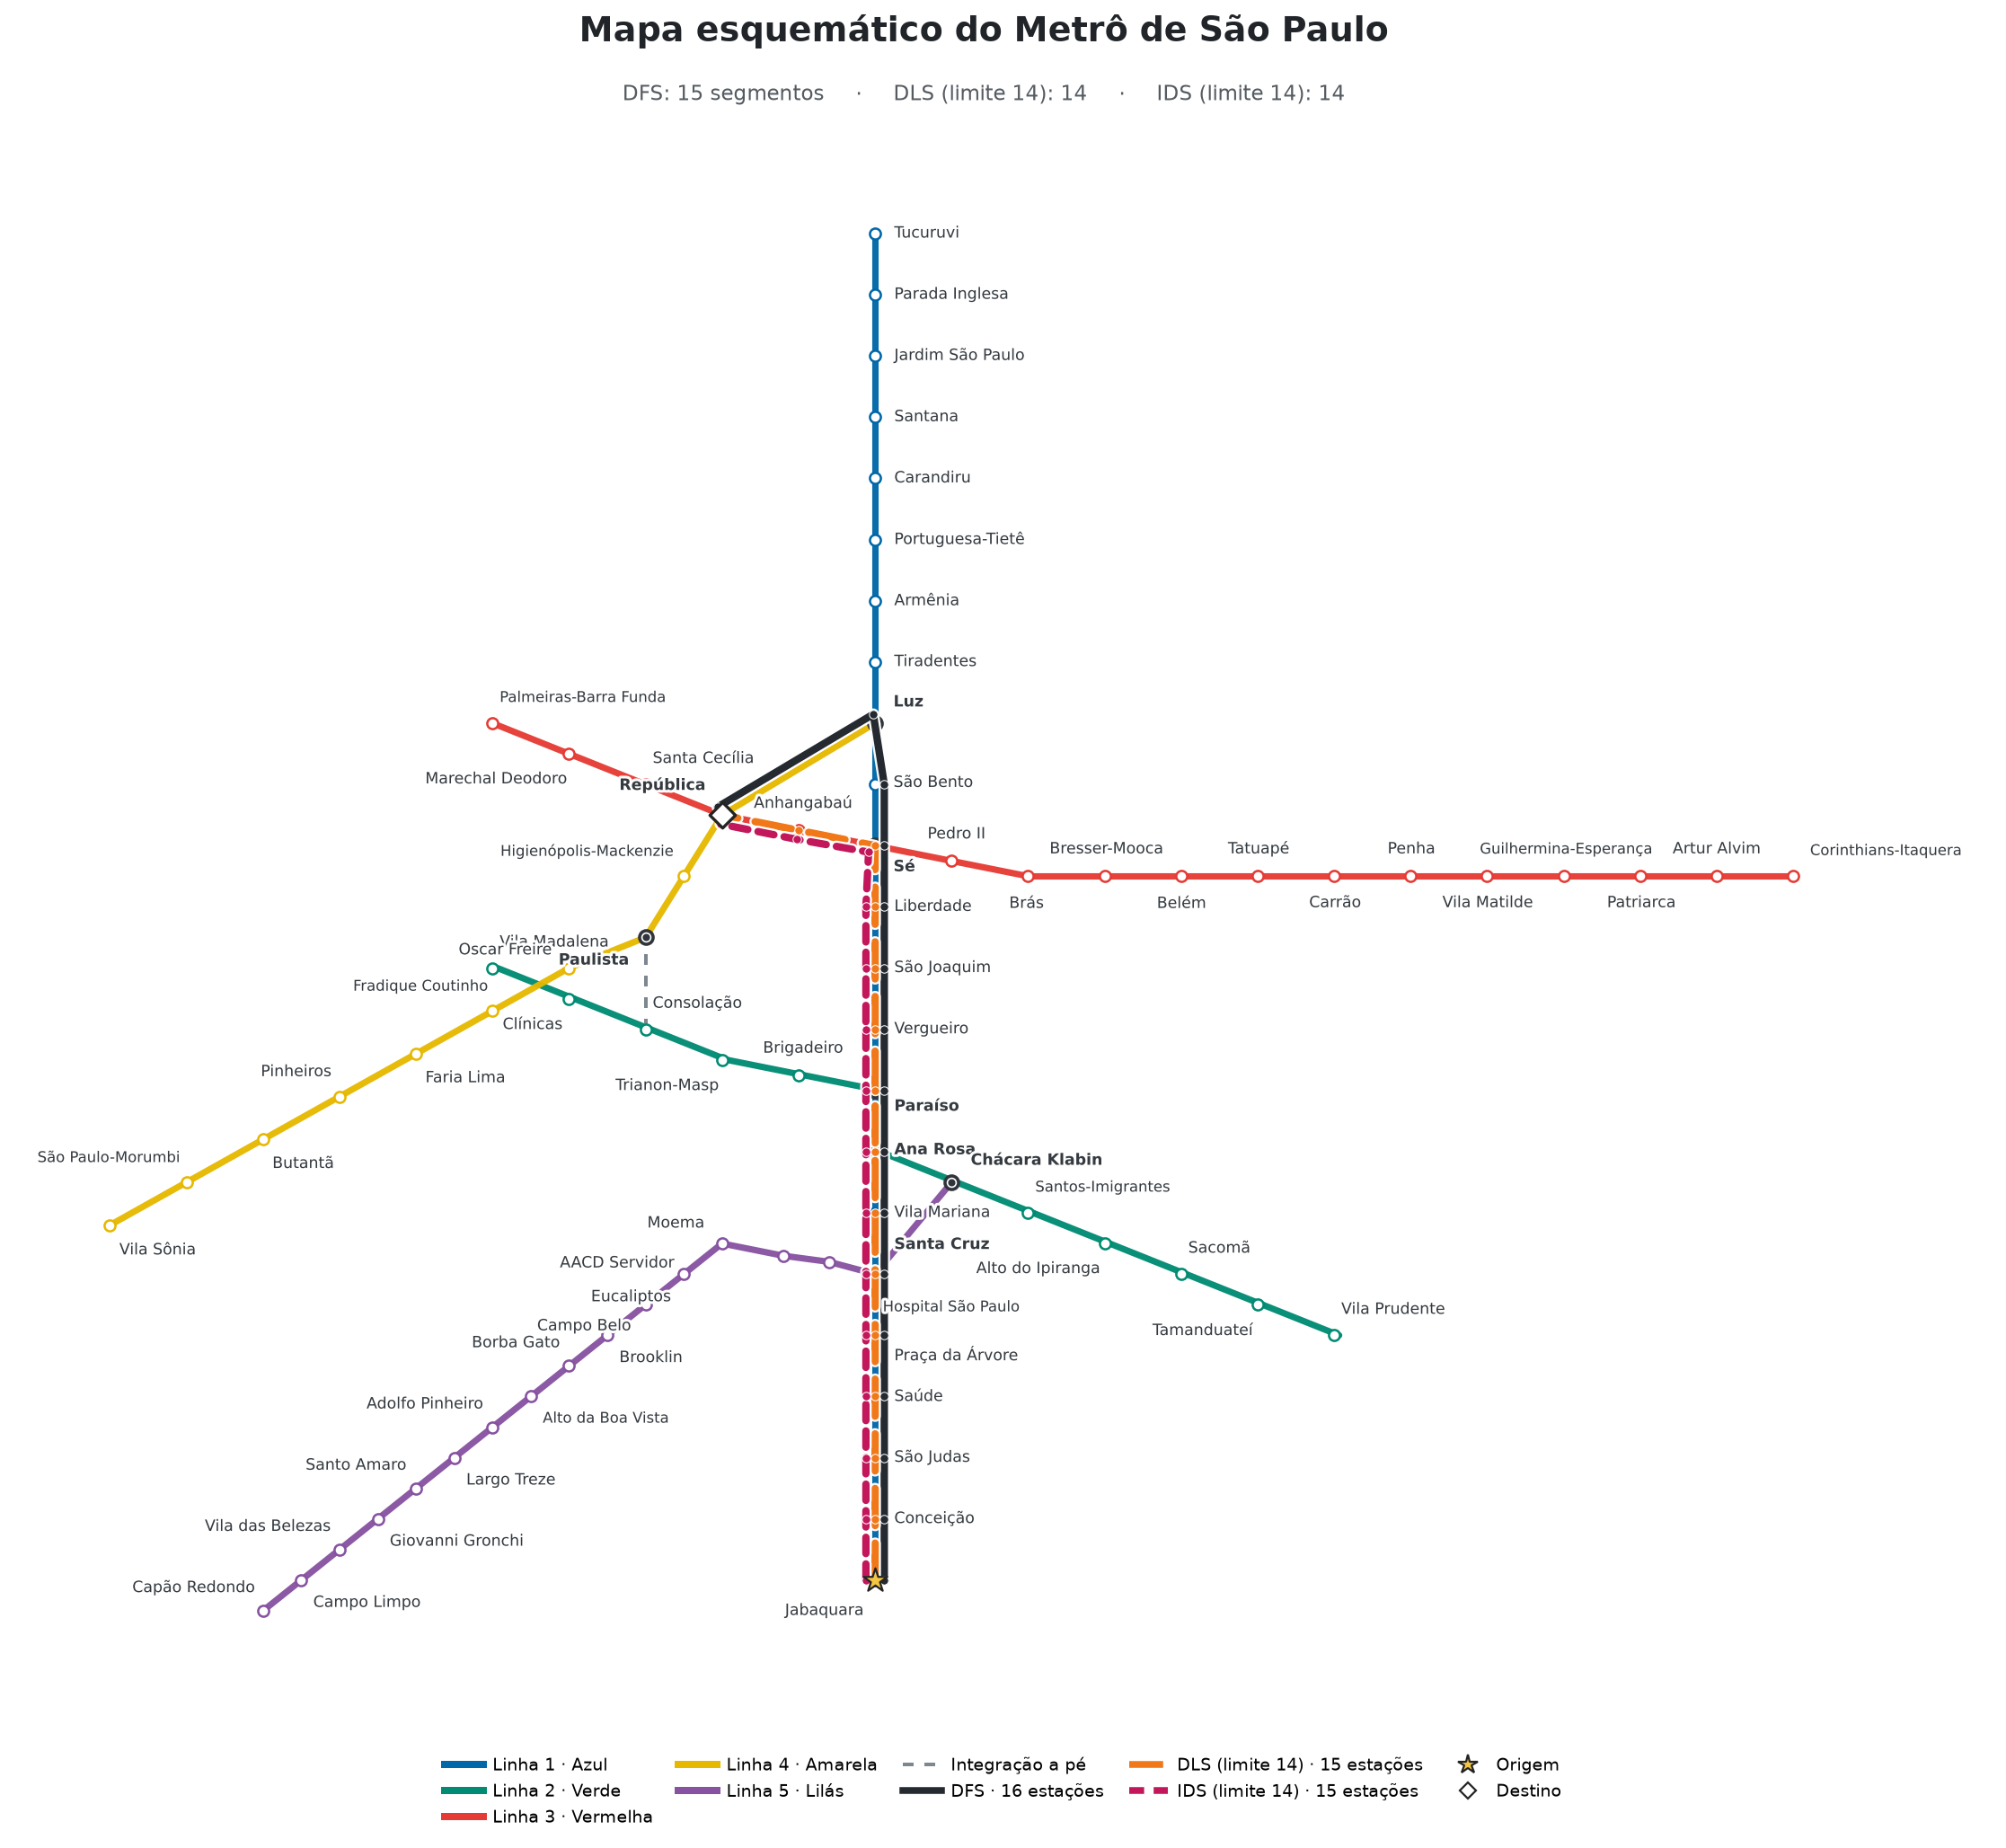

In [5]:
# Cores e sequências das linhas representadas no mapa oficial.
LINE_PATHS = {
    "Linha 1 · Azul": [str(i) for i in range(1, 24)],
    "Linha 3 · Vermelha": [str(i) for i in [24, 25, 26, 27, 28, 11, *range(29, 41)]],
    "Linha 2 · Verde": [str(i) for i in [41, 42, 43, 44, 45, 15, 16, *range(46, 52)]],
    "Linha 4 · Amarela": [str(i) for i in [9, 27, *range(52, 61)]],
    "Linha 5 · Lilás": [str(i) for i in [*range(61, 76), 18, 46]],
}
LINE_COLORS = {
    "Linha 1 · Azul": "#0067A8", "Linha 3 · Vermelha": "#E53B35",
    "Linha 2 · Verde": "#008B72", "Linha 4 · Amarela": "#E6B800",
    "Linha 5 · Lilás": "#8752A1",
}
LINE_ALIASES = {"Azul":"Linha 1 · Azul", "Vermelha":"Linha 3 · Vermelha",
                "Verde":"Linha 2 · Verde", "Amarela":"Linha 4 · Amarela",
                "Lilás":"Linha 5 · Lilás"}

Y_SCALE = 0.80  # comprime um pouco o eixo vertical para aproximar o formato do mapa oficial

def xy(id_estacao):
    e = estacoes[id_estacao]
    return np.array([e["x"], e["y"] * Y_SCALE], dtype=float)

fig, ax = plt.subplots(figsize=(18, 14), dpi=160)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Trilhos coloridos por linha. O pequeno deslocamento da Linha Verde diferencia o trecho compartilhado.
for nome_linha, caminho in LINE_PATHS.items():
    cor = LINE_COLORS[nome_linha]
    deslocamento_x = 0.065 if nome_linha == "Linha 2 · Verde" else 0.0
    for a, b in zip(caminho, caminho[1:]):
        p1, p2 = xy(a), xy(b)
        p1[0] += deslocamento_x
        p2[0] += deslocamento_x
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=cor, linewidth=3.2,
                solid_capstyle="round", zorder=1, alpha=0.96)

# Integração a pé entre Consolação (43) e Paulista (53).
p1, p2 = xy("43"), xy("53")
ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color="#7D8790", linewidth=1.8,
        linestyle=(0, (3, 3)), zorder=1.4, solid_capstyle="round")

# Estações e integrações.
intersecoes = {sid for sid, e in estacoes.items() if e["linha"] == "Intersecao"}
for sid, e in estacoes.items():
    px, py = xy(sid)
    eh_intersecao = sid in intersecoes
    cor = "#30343B" if eh_intersecao else LINE_COLORS[LINE_ALIASES.get(e["linha"], "Linha 1 · Azul")]
    ax.scatter([px], [py], s=46 if eh_intersecao else 30, marker="o", facecolor="white",
               edgecolor=cor, linewidth=1.6 if eh_intersecao else 1.15, zorder=3)
    if eh_intersecao:
        ax.scatter([px], [py], s=7, marker="o", color="#30343B", zorder=3.1)

# Define a linha de referência de cada rótulo. Os offsets centrais evitam sobreposição nas baldeações.
linha_rotulo_intersecao = {"9":"Linha 1 · Azul", "11":"Linha 1 · Azul", "15":"Linha 1 · Azul",
                           "16":"Linha 1 · Azul", "18":"Linha 1 · Azul", "27":"Linha 3 · Vermelha",
                           "46":"Linha 2 · Verde", "53":"Linha 4 · Amarela"}
linha_principal = {}
for nome_linha, caminho in LINE_PATHS.items():
    for sid in caminho:
        if sid not in linha_principal and estacoes[sid]["linha"] != "Intersecao":
            linha_principal[sid] = nome_linha
for sid, e in estacoes.items():
    if e["linha"] != "Intersecao":
        linha_principal[sid] = LINE_ALIASES.get(e["linha"], "Linha 1 · Azul")
    else:
        linha_principal[sid] = linha_rotulo_intersecao.get(sid, "Linha 1 · Azul")

offsets_rotulo = {
    "9":(0.24,0.17,"left","bottom"), "10":(0.24,0.02,"left","center"),
    "11":(0.24,-0.17,"left","top"), "15":(0.25,-0.10,"left","top"),
    "16":(0.25,0.02,"left","center"), "18":(0.25,0.28,"left","bottom"),
    "19":(0.25,-0.15,"left","top"),
    "27":(-0.24,0.28,"right","bottom"), "46":(0.25,0.18,"left","bottom"),
    "52":(-0.22,0.22,"right","bottom"), "53":(-0.25,-0.20,"right","top"),
    "54":(-0.27,0.13,"right","bottom"), "71":(-0.22,-0.18,"right","top"),
    "72":(-0.18,-0.20,"right","top"), "73":(-0.25,0.16,"right","bottom"),
    "74":(-1.45,-0.10,"right","center"), "75":(0.70,-0.50,"left","top"),
    "23":(-0.18,-0.30,"right","top"),
    "40":(0.22,0.23,"left","bottom"),
}
for sid, e in estacoes.items():
    px, py = xy(sid)
    if sid in offsets_rotulo:
        dx, dy, ha, va = offsets_rotulo[sid]
    else:
        nome_linha = linha_principal[sid]
        caminho = LINE_PATHS[nome_linha]
        idx = caminho.index(sid)
        if idx == 0:
            tangente = xy(caminho[1]) - xy(caminho[0])
        elif idx == len(caminho)-1:
            tangente = xy(caminho[-1]) - xy(caminho[-2])
        else:
            tangente = xy(caminho[idx+1]) - xy(caminho[idx-1])
        norma = np.linalg.norm(tangente)
        tangente = tangente/norma if norma else np.array([1.0,0.0])
        normal = np.array([-tangente[1], tangente[0]])
        sinal = 1 if nome_linha == "Linha 1 · Azul" else (1 if idx % 2 == 0 else -1)
        dx, dy = normal * 0.25 * sinal
        ha = "center" if abs(dx) < 0.06 else ("left" if dx > 0 else "right")
        va = "bottom" if dy > 0.04 else ("top" if dy < -0.04 else "center")
    tamanho = 7.4 if len(e["nome"]) >= 17 else 7.8
    ax.text(px+dx, py+dy, e["nome"], fontsize=tamanho, color="#343A40", ha=ha, va=va,
            fontweight="semibold" if sid in intersecoes else "normal", zorder=7, clip_on=False,
            path_effects=[pe.withStroke(linewidth=2.8, foreground="white", alpha=0.98)])

# Traçados dos três algoritmos. O deslocamento visual separa as rotas em trechos comuns.
def rota_deslocada(caminho, deslocamento):
    pontos = np.array([xy(sid) for sid in caminho])
    ajustados = []
    for i, p in enumerate(pontos):
        if i == 0:
            tangente = pontos[1] - pontos[0]
        elif i == len(pontos)-1:
            tangente = pontos[-1] - pontos[-2]
        else:
            tangente = pontos[i+1] - pontos[i-1]
        norma = np.linalg.norm(tangente)
        tangente = tangente/norma if norma else np.array([1.0,0.0])
        normal = np.array([-tangente[1], tangente[0]])
        ajustados.append(p + deslocamento * normal)
    return np.asarray(ajustados)

rotas_plot = [
    ("DFS", rota_dfs, "#252A31", "-", -0.12, f"DFS · {len(rota_dfs)} estações"),
    ("DLS", rota_dls, "#F07818", (0,(5,2.4)), 0.0, f"DLS (limite {limite_dls}) · {len(rota_dls)} estações"),
    ("IDS", rota_ids, "#C2185B", (0,(2.2,1.4)), 0.12, f"IDS (limite {limite_ids}) · {len(rota_ids)} estações"),
]
for nome, caminho, cor, estilo, deslocamento, rotulo in rotas_plot:
    pontos = rota_deslocada(caminho, deslocamento)
    linha, = ax.plot(pontos[:,0], pontos[:,1], color=cor, linewidth=3.7, linestyle=estilo,
                     zorder=5, solid_capstyle="round", dash_capstyle="round")
    linha.set_path_effects([pe.Stroke(linewidth=5.8, foreground="white", alpha=0.96), pe.Normal()])
    ax.scatter(pontos[:,0], pontos[:,1], s=18, color=cor, edgecolor="white", linewidth=0.45, zorder=5.5)

# Marcadores especiais para início e destino.
px, py = xy(origem)
ax.scatter([px], [py], s=155, marker="*", facecolor="#F5C542", edgecolor="#242424", linewidth=1.0, zorder=8)
px, py = xy(destino)
ax.scatter([px], [py], s=82, marker="D", facecolor="white", edgecolor="#242424", linewidth=1.5, zorder=8)

fig.suptitle("Mapa esquemático do Metrô de São Paulo", fontsize=17, fontweight="bold", color="#212529", y=0.978)
fig.text(0.5, 0.938,
         f"DFS: {len(rota_dfs)-1} segmentos     ·     DLS (limite {limite_dls}): {len(rota_dls)-1}     ·     IDS (limite {limite_ids}): {len(rota_ids)-1}",
         ha="center", va="center", fontsize=10.2, color="#555B61")

legenda = []
for nome_linha in ["Linha 1 · Azul", "Linha 2 · Verde", "Linha 3 · Vermelha", "Linha 4 · Amarela", "Linha 5 · Lilás"]:
    legenda.append(Line2D([0],[0], color=LINE_COLORS[nome_linha], linewidth=3.6, label=nome_linha))
legenda.append(Line2D([0],[0], color="#7D8790", linewidth=1.8, linestyle=(0,(3,3)), label="Integração a pé"))
for nome, caminho, cor, estilo, deslocamento, rotulo in rotas_plot:
    legenda.append(Line2D([0],[0], color=cor, linewidth=3.4, linestyle=estilo, label=rotulo))
legenda.extend([
    Line2D([0],[0], marker="*", markersize=10, markerfacecolor="#F5C542", markeredgecolor="#242424", linestyle="None", label="Origem"),
    Line2D([0],[0], marker="D", markersize=6, markerfacecolor="white", markeredgecolor="#242424", linestyle="None", label="Destino"),
])
ax.legend(handles=legenda, loc="upper center", bbox_to_anchor=(0.5,-0.055), ncol=5,
          frameon=False, fontsize=8.7, handlelength=2.2, columnspacing=1.45, handletextpad=0.55)
ax.set_xlim(-11.25, 14.6)
ax.set_ylim(-10.65, 8.55)
ax.set_aspect("equal", adjustable="box")
ax.axis("off")
fig.subplots_adjust(left=0.035, right=0.98, top=0.89, bottom=0.16)

ARQUIVO_PLOT = Path("mapa_rotas.png")
fig.savefig(ARQUIVO_PLOT, dpi=160, bbox_inches="tight", facecolor="white")
plt.show()
